# Reto Text-based Personality Computing: predicindo Big-5 a partir de Reddit
### **Equipo:** `VAIA` - **Integrantes:** Lucas Amado Oseira, María Lestón Geada e Iria Varela Palmás

**Obxectivo**: predicir, para cada usuario/a de test, as 5 dimensións Big Five (0–100) a partir das súas publicacións en Reddit.

**Métrica**: RMSE medio das 5 dimensións.

Estrutura do notebook:
1. Configuración e carga de datos
2. Limpeza básica e exploración
3. Preparación a nivel de usuario/a
4. Utilidades de validación (K-fold repetido, RMSE medio)
5. Baseline (media do train)
6. Modelo 1: TF-IDF + Ridge
7. Modelo 2: embeddings SBERT + Ridge
8. Ensemble e axuste de redución cara á media
9. Xeración dos CSV de envío
10. Resultados e discusión

Importamos as librerías necesarias para a práctica, que se realizará en Google Colab para garantizar velocidade na obtención dos resultados. Tamén definimos varias constantes: a ruta ao zip que contén os CSVs que empregaremos, a ruta ao directorio no que se descomprimirá dito zip, o nome do equipo e as 5 características a predicir. Ademáis, fixaremos unha semente que nos garantice a reproducibilidade dos resultados.

In [1]:
import re, numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import KFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
import zipfile, os
from google.colab import drive

# Montamos Google Drive para acceder aos arquivos
drive.mount('/content/drive')

# Definimos constantes
ZIP_PATH = "/content/drive/MyDrive/material.zip"
DATA = "/content/material"
TEAM = "VAIA"
TRAITS = ["agreeableness","openness","conscientiousness","extraversion","neuroticism"]
SEED = 2710

Mounted at /content/drive


## 1. Configuración e carga de datos

Comezamos descomprimindo o zip e cargando os tres CSVs.

In [2]:
# Descomprimimos o zip desde Drive e lemos os CSVs
os.makedirs(DATA, exist_ok=True)
with zipfile.ZipFile(ZIP_PATH, "r") as z:
    z.extractall(DATA)

# Listamos os arquivos descomprimidos
print(os.listdir(DATA))

# Lemos os CSVs
posts = pd.read_csv(f"{DATA}/posts_v2.csv")   # Posts
tr = pd.read_csv(f"{DATA}/authors_train.csv") # Datos de adestramento
te = pd.read_csv(f"{DATA}/authors_test.csv")  # Datos de test

# Mostramos información básica dos tres dataframes
print("\nposts, train, test:", posts.shape, tr.shape, te.shape)
print("posts columns:", posts.columns.tolist())
print("train columns:", tr.columns.tolist())
print("test columns:", te.columns.tolist())
posts.head()

['authors_train.csv', 'authors_test.csv', 'posts_v2.csv']

posts, train, test: (3125358, 2) (1288, 6) (323, 6)
posts columns: ['username', 'body']
train columns: ['username', 'agreeableness', 'openness', 'conscientiousness', 'extraversion', 'neuroticism']
test columns: ['username', 'agreeableness', 'openness', 'conscientiousness', 'extraversion', 'neuroticism']


,username,body
0,-Areopagan-,Your first and second question is the same que...
1,-Areopagan-,"I have two friends. I alienate everyone, event..."
2,-Areopagan-,I suggest the future. You aren't going back in...
3,-Areopagan-,Yeah I wouldnt want to deal with someone like ...
4,-BigSexy-,I've been asked to cum everywhere with my ex j...


## 2. Limpeza básica e exploración

A continuación, realizamos unha pequena limpeza preliminar do dataset.

As columnas principais dos posts son duas: `username`, que identifica o/a autor/a e tamén está presente nos outros duos arquivos contidos en *tr* e *te*, e `body`, que contén o texto da publicación.

Procedemos a contar o número de nulos por columna.

In [3]:
# Contamos número de nulos por columna
print("Nulos en posts:"); print(posts.isnull().sum())
print("\nNulos nos datos de adestramento:"); print(tr.isnull().sum())
print("\nNulos nos datos de test:"); print(te.isnull().sum())

Nulos en posts:
username     0
body        20
dtype: int64

Nulos nos datos de adestramento:
username              0
agreeableness         4
openness             18
conscientiousness     4
extraversion          3
neuroticism           7
dtype: int64

Nulos nos datos de test:
username               0
agreeableness        323
openness             323
conscientiousness    323
extraversion         323
neuroticism          323
dtype: int64


Vemos que non existen nulos na colunma `username`, o que nos indica que todos os posts teñen un/unha autor/a asociado/a, e que tanto nos posts coma nos datos de adestramento os nulos presentes son mínimos. O que faremos para desfacernos deles será eliminar as publicacións sen texto de *posts*.

Nos datos de test, as 5 columnas están baleiras, pois son os valores a predicir.

En train (*tr*), non imputaremos as etiquetas que faltan. Imputar a media crearía un pico artificial e faría que avaliásemos contra valores inventados. En vez diso, cada trazo adestrarase e avaliarase só cos/as usuarios/as que teñan valor real nese trazo. Por iso, conservaremos algúns *NaN*.

In [4]:
# Definimos as columnas de usuario e texto de posts
USER_COL = "username"
TEXT_COL = "body"

# Borramos filas con body nulo e convertimos a string
posts = posts.dropna(subset=[TEXT_COL]).copy()
posts[TEXT_COL] = posts[TEXT_COL].astype(str)

# Comprobamos que as columnas restantes existan
assert USER_COL in posts.columns and TEXT_COL in posts.columns, "Axusta USER_COL / TEXT_COL"

# NON TOCAR AINDA
# Eliminamos os nulos de tr para cada trait
# for trait in TRAITS:
#     tr_trait = tr.dropna(subset=[trait])

A continuación, vemos a distribución das puntuacións de personalidade dos datos de adestramento, tanto nunha táboa descriptiva como en histogramas de forma máis visual. Tamén observamos as correlacións entre trazos e a distribución do número e lonxitude das publicacións.

       agreeableness  openness  conscientiousness  extraversion  neuroticism
count         1284.0    1270.0             1284.0        1285.0       1281.0
mean            42.8      62.6               39.5          37.3         49.7
std             31.2      27.8               30.0          30.6         32.3
min              0.0       0.0                0.0           0.0          0.0
25%             14.0      44.0               13.0          10.0         19.0
50%             40.0      69.0               35.0          30.0         49.0
75%             70.0      86.8               63.0          62.0         82.0
max            100.0      99.0               99.0          99.0         99.0


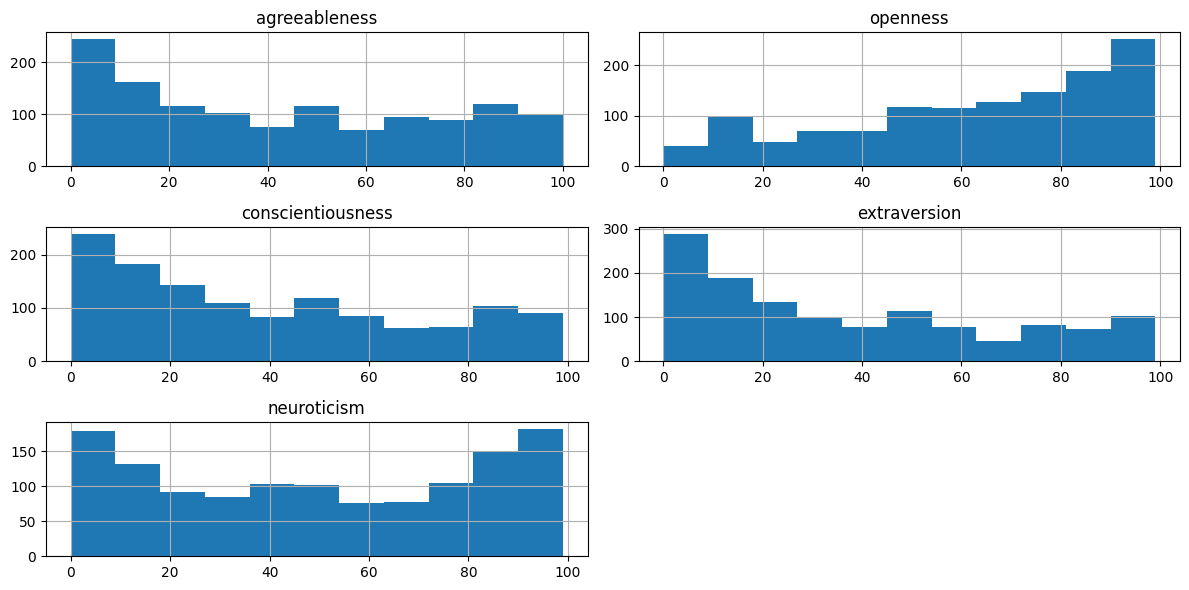

Correlacións entre trazos:
                   agreeableness  openness  conscientiousness  extraversion  \
agreeableness               1.00      0.12               0.05          0.04   
openness                    0.12      1.00              -0.05          0.22   
conscientiousness           0.05     -0.05               1.00          0.04   
extraversion                0.04      0.22               0.04          1.00   
neuroticism                 0.05     -0.00              -0.26         -0.25   

                   neuroticism  
agreeableness             0.05  
openness                 -0.00  
conscientiousness        -0.26  
extraversion             -0.25  
neuroticism               1.00  

Publicacións por usuario/a: count     1572.0
mean      1988.1
std       4554.7
min          1.0
25%         85.0
50%        432.0
75%       1865.5
max      66350.0
dtype: float64

Lonxitude media das publicacións: 37.8 palabras


In [5]:
print(tr[TRAITS].describe().round(1))
tr[TRAITS].hist(bins=11, figsize=(12,6))
plt.tight_layout()
plt.show()

# Correlacións entre traits
print("Correlacións entre trazos:"); print(tr[TRAITS].corr().round(2))

# Exploración de datos de posts
n = posts.groupby(USER_COL).size()
print("\nPublicacións por usuario/a:", n.describe().round(1))
print("\nLonxitude media das publicacións:", posts[TEXT_COL].astype(str).str.split().str.len().mean().round(1), "palabras")

## 3. Agregación a nivel de usuario/a

Sabemos que cada exemplo de adestramento é un/unha usuario/a, polo que debemos reducir os millóns de publicacións a un texto ou vector por persoa.

Para iso, realizaremos un **mostreo aleatorio** de ata `MAX_POSTS` publicacións por usuario/a. Poderíamos quedarnos só coas primeiras ou concatenar todo e cortar, pero decidimos non facelo para non descartar case todo o texto dos usuarios máis activos, ademáis de que non resultaría representativo.

Realizaremos tamén unha nova **limpeza**, que sustituirá todas as *URLS* por `URL` e normalizará os espazos. Finalmente, **concatenaremos** as publicacións de cada usuario/a, establecendo un máximo de `MAX_CHARS` para limitar o custo computacional.

In [6]:
MAX_POSTS   = 300 # max publicacións por usuario para o TF-IDF, son aleatorias
MAX_CHARS = 20000 # max chars do texto concatenado por usuario

# Función para limpar texto: eliminamos URLs e reducimos espazos
def clean(t):
    t = re.sub(r"http\S+", " URL ", str(t))
    return re.sub(r"\s+", " ", t).strip()

# Realizamos un mostreo aleatorio de publicacións barallando e limitando a MAX_POSTS por usuario
sample = (posts.sample(frac=1, random_state=SEED).groupby(USER_COL).head(MAX_POSTS).copy())
sample["_t"] = sample[TEXT_COL].map(clean) # limpamos só a mostra
sample = sample[sample["_t"].str.len() > 0] # eliminamos publicacións baleiras tras limpar

# Concatenamos as publicacións por usuario e limitamos a MAX_CHARS
user_text = sample.groupby(USER_COL)["_t"].apply(lambda s: " ".join(s)[:MAX_CHARS])

train = tr.merge(user_text.rename("text"), left_on=USER_COL, right_index=True, how="left")
test  = te.merge(user_text.rename("text"), left_on=USER_COL, right_index=True, how="left")

# Contamos os usuarios sen texto en train e test antes de sustituir os nulos
print(train["text"].isna().sum(), "posts en train sen texto e", test["text"].isna().sum(), "posts en test sen texto")
train["text"] = train["text"].fillna("")
test["text"] = test["text"].fillna("")

# Comprobamos que non quedan nulos
print(f"Usuarios sin texto -> Train: {train['text'].isna().sum()} | Test: {test['text'].isna().sum()}")

# Separamos os textos e etiquetas de adestramento
texts = train["text"].values
test_texts = test["text"].values

Y = train[TRAITS].values.astype(float)

29 posts en train sen texto e 10 posts en test sen texto
Usuarios sin texto -> Train: 0 | Test: 0


## 4. Utilidades de validación (K-fold, RMSE medio)

Para comparar os modelos empregamos a validación cruzada K-fold (k=5), que se repetirá `N_REPEATS` veces con particións distintas para reducir o ruído que provocan as pequenas diferenzas azarosas de RMSE.

Debemos ter en conta que o RMSE se vai calcular só sobre as etiquetas reais, ignorando os nulos. 

In [7]:
# RMSE de cada trazo ignorando nulos
def rmse_by_trait(y, p):
    return np.sqrt(np.nanmean((y-p)**2, axis=0))

# RMSE medio ignorando nulos
def rmse_mean(y, p):
    return rmse_by_trait(y, p).mean()

# Convertimos cada array de predición a diccionario con traits
def as_dict(arr):
    return {t: round(float(v), 2) for t, v in zip(TRAITS, arr)}

Realizaremos un adestramento e predicción con Regresión Ridge Multisaída, onde cada trazo se adestra só coas filas que presentan etiqueta nese trazo. As predicións recórtanse a [0, 100], que é o rango válido.

In [8]:
def ridge_multi(A, Ytr, B, alpha):
    p = np.zeros((B.shape[0], len(TRAITS))) # un Ridge por trazo empregando só as filas con etiqueta
    for i in range(len(TRAITS)):
        a = alpha[i] if np.ndim(alpha) else alpha # alpha pode ser un escalar ou un valor por trazo
        ok = ~np.isnan(Ytr[:, i]) # filas con etiqueta para o trazo i
        p[:, i] = Ridge(alpha=a, random_state=SEED).fit(A[ok], Ytr[ok, i]).predict(B) # predición para o trazo i
    return np.clip(p, 0, 100) # limitamos predicións entre 0 e 100

Finalmente, gardamos as predicións *out-of-fold (oof)* de cada modelo, que permiten combinar modelos e analizar erros sen volver adestrar. `cv_grid` proba varios valores de `alpha` do Ridge e escolle o mellor por trazo. Como a escolla e a avaliación usan os mesmos datos, o RMSE resultante é lixeiramente optimista, pero o efecto é pequeno, pois só se axusta un hiperparámetro por trazo.

In [9]:
N_REPEATS = 2 # repeticións do K-fold

# Realizamos CV e devolvemos o RMSE medio, un diccionario de RMSE por trazo e a primeira predición OOF
def cv_eval(fit_predict, X, Y, k=5, repeats=N_REPEATS):
    scores, pers, first_oof = [], [], None
    for r in range(repeats):
        oof = np.zeros_like(Y, dtype=float)
        for tri, vai in KFold(k, shuffle=True, random_state=SEED + r).split(X):
            oof[vai] = fit_predict(X[tri], Y[tri], X[vai])
        scores.append(rmse_mean(Y, oof))
        pers.append(rmse_by_trait(Y, oof))
        if first_oof is None:
            first_oof = oof
    return np.mean(scores), as_dict(np.mean(pers, axis=0)), first_oof


# ESTO IGUAL O PODEMOS QUITAR
# K-fold repetido probando varios alphas e devolvendo a táboa de resultados, mellor alpha por trazo, RMSE medio, diccionario de RMSE por trazo e predicións OOF
# featurize(tri, vai) -> (A_train, A_val) para que o TF-IDF se axuste dentro de cada fold
def cv_grid(featurize, alphas, k=5, repeats=N_REPEATS):
    per = {a: [] for a in alphas}; first = None
    for r in range(repeats):
        oofs = {a: np.zeros_like(Y) for a in alphas}
        for tri, vai in KFold(k, shuffle=True, random_state=SEED + r).split(Y):
            A, B = featurize(tri, vai)
            for a in alphas:
                oofs[a][vai] = ridge_multi(A, Y[tri], B, a)
        for a in alphas: per[a].append(rmse_by_trait(Y, oofs[a]))
        if first is None: first = oofs
    per = {a: np.mean(per[a], axis=0) for a in alphas}
    table = pd.DataFrame(per, index=TRAITS).T # filas = alpha, columnas = trazos
    table["media"] = table.mean(axis=1)
    best = [alphas[int(np.argmin([per[a][j] for a in alphas]))] for j in range(len(TRAITS))] # mellor alpha por trazo
    oof = np.column_stack([first[best[j]][:, j] for j in range(len(TRAITS))])
    score = np.mean([per[best[j]][j] for j in range(len(TRAITS))])
    return table, best, score, as_dict([per[best[j]][j] for j in range(len(TRAITS))]), oof

RESULTS, OOF = {}, {}   # RMSE medio por trazo e predicións oof de cada modelo

## 5. Baseline: predicir a media do train

A Referencia mínima é predicir para todos/as os/as usuarios/as a media de cada trazo, calculada só co train de cada fold. Calquera modelo útil debe superala.

In [10]:
# Modelo base: predición constante co valor medio de cada trazo ignorando nulos
base = lambda Xtr, Ytr, Xva: np.tile(np.nanmean(Ytr, axis=0), (len(Xva),1))
s_base, d_base, o = cv_eval(base, texts, Y)

# Gardamos os resultados do modelo base
RESULTS["baseline"], OOF["baseline"] = (s_base, d_base), o

# Imprimimos o RMSE medio e o diccionario de RMSE por trazo do modelo base
print("Baseline RMSE:", round(s_base, 3), d_base)

Baseline RMSE: 30.398 {'agreeableness': 31.23, 'openness': 27.79, 'conscientiousness': 30.04, 'extraversion': 30.63, 'neuroticism': 32.3}


## 6. Modelo 1: TF-IDF + Ridge

Realizamos unha vectorización clásica con unigramas e bigramas e regresión lineal regularizada (*Ridge*), cun modelo por trazo. O vectorizador axústase dentro de cada fold, só co seu train, para evitar leakage.

Facemos probas con varios `alpha` para ver que forza de regularización convén e escollemos o mellor por trazo. En execucións previas realizamos experimentos cos valores [1, 3, 10, 30], dando como mellor valor o menor probado (1), polo que esta nova rede inclúe valores máis baixos (0.1, 0.3).

In [11]:
# Creamos o vectorizador TF-IDF
def make_vec():
    return TfidfVectorizer(sublinear_tf=True, # para reducir o peso das palabras moi frecuentes
                           min_df=2, max_df=0.9, # eliminamos palabras moi raras e moi frecuentes
                           ngram_range=(1, 2), # incluimos unigramas e bigramas
                           max_features=200000) # limitamos o número de features para reducir a memoria e tempo de adestramento

# Featurizamos os datos de adestramento e validación usando TF-IDF
def feat_tfidf(tri, vai):
    vec = make_vec()
    return vec.fit_transform(texts[tri]), vec.transform(texts[vai])

# Creamos o modelo TF-IDF + Ridge e realizamos CV para varios alphas
alphas = [0.1, 0.3, 1, 3, 10]
tab_tfidf, alpha_tfidf, s, d, o = cv_grid(feat_tfidf, alphas)

RESULTS["tfidf_ridge"], OOF["tfidf_ridge"] = (s, d), o
print("RMSE por alpha (filas) e trazo (columnas):")
display(tab_tfidf.round(2))
print("Mellor alpha por trazo:", dict(zip(TRAITS, alpha_tfidf)))
print("TF-IDF + Ridge  RMSE medio:", round(s, 3), d)

RMSE por alpha (filas) e trazo (columnas):


,agreeableness,openness,conscientiousness,extraversion,neuroticism,media
0.1,30.52,27.29,29.52,29.47,31.25,29.61
0.3,30.53,27.28,29.52,29.54,31.29,29.63
1.0,30.62,27.33,29.58,29.76,31.47,29.75
3.0,30.83,27.46,29.73,30.09,31.75,29.97
10.0,31.05,27.63,29.90,30.39,32.05,30.20


Mellor alpha por trazo: {'agreeableness': 0.1, 'openness': 0.3, 'conscientiousness': 0.3, 'extraversion': 0.1, 'neuroticism': 0.1}
TF-IDF + Ridge  RMSE medio: 29.608 {'agreeableness': 30.52, 'openness': 27.28, 'conscientiousness': 29.52, 'extraversion': 29.47, 'neuroticism': 31.25}


## 7. Modelo 2: embeddings SBERT + Ridge

Dado que os embeddings capturan o significado semántico, no segundo modelo codificaremos publicacións con *Sentence-BERT* (`all-MiniLM-L6-v2`, 384 dimensións). Posteriormente faremos a media dos embeddings por usuario/a, empregando ata `N_EMB_POSTS` publicacións aleatorias da mostra da sección 3. Despois aplicamos o mesmo Ridge por trazo.

O cálculo é custoso, polo que os embeddings gárdanse en disco (`EMB_FILE`, en Drive) e, se o ficheiro existe, cárganse en vez de recalcularse. Debido precisamente a este gran custo, realizamos os cálculos con GPU.

In [12]:
!pip install sentence-transformers

In [13]:
N_EMB_POSTS = 100 # publicacións max por usuario/a para os embeddings SBERT, son aleatorias
EMB_FILE = os.path.join(os.path.dirname(ZIP_PATH), "emb_sbert.npz")  # caché dos embeddings xa calculados (en Drive)

# Obtemos todos os usuarios
users = pd.concat([train[USER_COL], test[USER_COL]]).unique()

if os.path.exists(EMB_FILE):
    # Cargamos os embeddings xa calculados
    d_ = np.load(EMB_FILE, allow_pickle=True)
    E = dict(zip(d_["users"], d_["emb"]))
    print("Embeddings cargados de", EMB_FILE)
else:
    from sentence_transformers import SentenceTransformer
    sbert = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")

    # Publicacións (xa limpas e baralladas) de cada usuario/a, limitadas a N_EMB_POSTS
    g = (sample[sample[USER_COL].isin(users)].groupby(USER_COL)["_t"].apply(lambda s: list(s)[:N_EMB_POSTS]))
    
    # Embedding de usuario/a = media dos embeddings das súas publicacións
    E = {u: sbert.encode(g[u], batch_size=64, normalize_embeddings=True).mean(axis=0) for u in users if u in g.index}
    np.savez(EMB_FILE, users=np.array(list(E.keys()), dtype=object), emb=np.vstack(list(E.values()))) # vstack para gardar como array 2D
    print("Embeddings calculados e gardados en", EMB_FILE)

print("Número de usuarios con embedding:", len(E), "de", len(users))

Embeddings cargados de /content/drive/MyDrive/emb_sbert.npz
Número de usuarios con embedding: 1572 de 1611


In [15]:
# Matriz de embeddings (ceros para os/as usuarios/as sen texto)
dim = len(next(iter(E.values()))) # dimensión do embedding

# Creamos as matrices de embeddings para adestramento e test, empregando ceros para os usuarios sen embedding
Etr = np.vstack([E.get(u, np.zeros(dim)) for u in train[USER_COL]])
Ete = np.vstack([E.get(u, np.zeros(dim)) for u in test[USER_COL]])

# Featurizamos os datos de adestramento e validación empregando os embeddings SBERT
feat_sbert = lambda tri, vai: (Etr[tri], Etr[vai])
tab_sbert, alpha_sbert, s, d, o = cv_grid(feat_sbert, alphas)

RESULTS["sbert_ridge"], OOF["sbert_ridge"] = (s, d), o
print("RMSE por alpha (filas) e trazo (columnas):"); display(tab_sbert.round(2))
print("Mellor alpha por trazo:", dict(zip(TRAITS, alpha_sbert)))
print("SBERT + Ridge  RMSE medio:", round(s, 3), d)

RMSE por alpha (filas) e trazo (columnas):


,agreeableness,openness,conscientiousness,extraversion,neuroticism,media
0.1,31.66,28.16,30.71,29.61,32.47,30.52
0.3,30.99,27.73,30.01,29.32,31.82,29.97
1.0,30.74,27.59,29.75,29.53,31.64,29.85
3.0,30.79,27.60,29.79,29.95,31.77,29.98
10.0,30.96,27.67,29.91,30.33,32.02,30.18


Mellor alpha por trazo: {'agreeableness': 1, 'openness': 1, 'conscientiousness': 1, 'extraversion': 0.3, 'neuroticism': 1}
SBERT + Ridge  RMSE medio: 29.806 {'agreeableness': 30.74, 'openness': 27.59, 'conscientiousness': 29.75, 'extraversion': 29.32, 'neuroticism': 31.64}


## 8. Ensemble e redución cara á media

Dado que os dous modelos ven os textos de forma distinta (palabras exactas no primeiro vs. significado con SBERT), as súas predicións teñen erros parcialmente independentes. Por este motivo, probamos dúas melloras sobre as predicións *out-of-fold*:

- **Ensemble**: media das predicións de TF-IDF e SBERT.
- **Redución cara á media (*shrinkage*)**: `p = lambda x pred + (1 − lambda) x media`. O RMSE penaliza moito as predicións con demasiada varianza e a sinal de personalidade nos textos é débil, polo que encollemos as predicións cara á media para tentar corrixilo. O lamba escóllese por trazo.

Para escoller lambda sen facer trampas, a "media" que usamos nas predicións *out-of-fold* é a calculada fóra de cada fold (`OOF["baseline"]`), non a de todo o train.

Ensemble RMSE: 29.539 {'agreeableness': 30.46, 'openness': 27.26, 'conscientiousness': 29.55, 'extraversion': 29.18, 'neuroticism': 31.23}


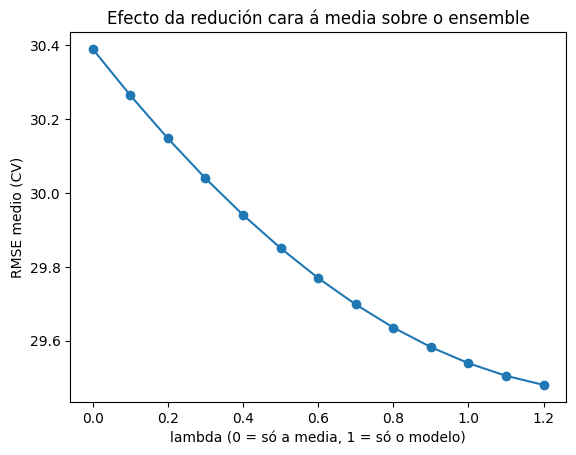

lambda óptimo por trazo: {'agreeableness': 1.2, 'openness': 1.2, 'conscientiousness': 1.2, 'extraversion': 1.2, 'neuroticism': 1.2}
Ensemble + shrink RMSE: 29.48 {'agreeableness': 30.42, 'openness': 27.23, 'conscientiousness': 29.52, 'extraversion': 29.08, 'neuroticism': 31.15}


In [16]:
mu = np.nanmean(Y, axis=0)       # media de todo o train, únicamente para predicir o test
oof_mu = OOF["baseline"]         # media calculada fóra de cada fold (sen leakage)

# Ensemble
oof_ens = (OOF["tfidf_ridge"] + OOF["sbert_ridge"]) / 2 # media das predicións dos modelos

RESULTS["ensemble"] = (rmse_mean(Y, oof_ens), as_dict(rmse_by_trait(Y, oof_ens)))
OOF["ensemble"] = oof_ens
print("Ensemble RMSE:", round(RESULTS["ensemble"][0], 3), RESULTS["ensemble"][1])

# Redución cara á media sobre o ensemble
# lambda escollido por trazo
lams = np.round(np.linspace(0, 1.2, 13), 2) # valores de lambda a probar
per_l = np.array([rmse_by_trait(Y, l * oof_ens + (1 - l) * oof_mu) for l in lams]) # calculamos o RMSE por trazo para cada lambda
                                                                                    # o resultado é unha matriz de tamaño (nº lambda, nº trazos) = (nº lambda, 5)
LAM = lams[per_l.argmin(axis=0)] # lambda óptimo por trazo
oof_sh = LAM * oof_ens + (1 - LAM) * oof_mu # predicións OOF do ensemble con shrink

RESULTS["ensemble_shrink"] = (rmse_mean(Y, oof_sh), as_dict(rmse_by_trait(Y, oof_sh)))
OOF["ensemble_shrink"] = oof_sh

plt.plot(lams, per_l.mean(axis=1), marker="o")
plt.xlabel("lambda (0 = só a media, 1 = só o modelo)"); plt.ylabel("RMSE medio (CV)")
plt.title("Efecto da redución cara á media sobre o ensemble"); plt.show()
print("lambda óptimo por trazo:", dict(zip(TRAITS, LAM.tolist())))
print("Ensemble + shrink RMSE:", round(RESULTS["ensemble_shrink"][0], 3), RESULTS["ensemble_shrink"][1])

## 9. Xeración dos CSV de envío

Formato: `team_name, variant_name, username, agreeableness, openness, conscientiousness, extraversion, neuroticism`; ficheiro `nome_equipo_nome_variante.csv`.

Para cada variante reentrenamos o modelo con todo o train, cos mellores `alpha` por trazo atopados na validación, e predicimos o test. As variantes realizadas son as seguintes:

- `tfidf_ridge`: Modelo 1.
- `sbert_ridge`: Modelo 2.
- `ensemble_shrink`: media dos dous modelos con redución cara á media.

In [ ]:
def make_submission(variant, preds):
    # Creamos o DataFrame de saída coas predicións, limitando os valores entre 0 e 100
    df = pd.DataFrame(np.clip(preds,0,100), columns=TRAITS)
    df.insert(0, "username", test[USER_COL].values)
    df.insert(0, "variant_name", variant)
    df.insert(0, "team_name", TEAM)

    # Comprobamos que os datos sexan válidos
    assert len(df) == len(te) and df[TRAITS].notna().all().all(), "Erro: o DataFrame de saída non ten a lonxitude correcta ou contén valores nulos"
    
    # Gardamos o DataFrame nun CSV co nome do equipo e a variante
    fn = f"{TEAM}_{variant}.csv"
    df.to_csv(fn, index=False)
    print("Gardado", fn)
    return df


# Modelo base: media de todo o train
sub1 = make_submission("baseline", base(texts, Y, test["text"].values))

# Modelo 1: TF-IDF + Ridge adestrado con todo o train
vec = make_vec()
P_tfidf = ridge_multi(vec.fit_transform(texts), Y, vec.transform(test_texts), alpha_tfidf)
sub2 = make_submission("tfidf_ridge", P_tfidf)

# Modelo 2: SBERT + Ridge adestrado con todo o train
P_sbert = ridge_multi(Etr, Y, Ete, alpha_sbert)
sub3 = make_submission("sbert_ridge", P_sbert)

# Ensemble + redución cara á media (lambda por trazo, media de todo o train)
P_ens = (P_tfidf + P_sbert) / 2
sub4 = make_submission("ensemble_shrink", LAM * P_ens + (1 - LAM) * mu)

Gardado VAIA_baseline.csv en  /content
Gardado VAIA_tfidf_ridge.csv en  /content
Gardado VAIA_sbert_ridge.csv en  /content
Gardado VAIA_ensemble_shrink.csv en  /content


In [43]:
print("Baseline:")
print(sub1.head())
print("\nTF-IDF + Ridge:")
print(sub2.head())
print("\nSBERT + Ridge:")
print(sub3.head())
print("\nEnsemble + Shrink:")
print(sub4.head())

Baseline:
  team_name variant_name           username  agreeableness   openness  \
0      VAIA     baseline         libelle156      42.773364  62.579921   
1      VAIA     baseline  drawtheApocalypse      42.773364  62.579921   
2      VAIA     baseline    I_hate_kittens_      42.773364  62.579921   
3      VAIA     baseline       gillybean103      42.773364  62.579921   
4      VAIA     baseline        DivinePetal      42.773364  62.579921   

   conscientiousness  extraversion  neuroticism  
0          39.477414     37.261089    49.706479  
1          39.477414     37.261089    49.706479  
2          39.477414     37.261089    49.706479  
3          39.477414     37.261089    49.706479  
4          39.477414     37.261089    49.706479  

TF-IDF + Ridge:
  team_name variant_name           username  agreeableness   openness  \
0      VAIA  tfidf_ridge         libelle156      43.402512  60.486092   
1      VAIA  tfidf_ridge  drawtheApocalypse      45.890070  49.974976   
2      VAIA  tf

In [42]:
# Copiamos os CSV a Drive para non perdelos cando se peche a sesión de Colab
import shutil
for v in ["baseline", "tfidf_ridge", "sbert_ridge", "ensemble_shrink"]:
    shutil.copy(f"{TEAM}_{v}.csv", "/content/drive/MyDrive/")
print("CSVs copiados a Google Drive")

CSVs copiados a Google Drive


# REVISAR APARTADO 10 (CLAUDIA)

## 10. Resultados e discusión

### 10.1 Táboa comparativa

RMSE medio e por trazo en validación cruzada para todos os modelos. Todos os números proceden da mesma validación (mesmas particións), polo que son comparables.

,RMSE medio,agreeableness,openness,conscientiousness,extraversion,neuroticism
ensemble_shrink,29.480,30.42,27.23,29.52,29.08,31.15
ensemble,29.539,30.46,27.26,29.55,29.18,31.23
tfidf_ridge,29.608,30.52,27.28,29.52,29.47,31.25
sbert_ridge,29.806,30.74,27.59,29.75,29.32,31.64
baseline,30.398,31.23,27.79,30.04,30.63,32.30


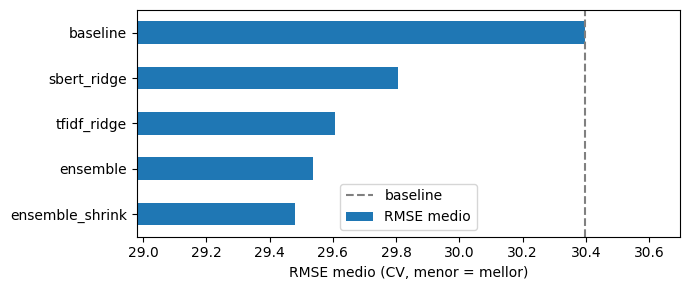

In [18]:
tabla = pd.DataFrame({k: {"RMSE medio": round(v[0], 3), **v[1]} for k, v in RESULTS.items()}).T
tabla = tabla.sort_values("RMSE medio")
display(tabla)

ax = tabla["RMSE medio"].plot.barh(figsize=(7, 3))
ax.axvline(RESULTS["baseline"][0], color="gray", ls="--", label="baseline")
ax.set_xlim(tabla["RMSE medio"].min() - 0.5, tabla["RMSE medio"].max() + 0.3)
ax.set_xlabel("RMSE medio (CV, menor = mellor)"); ax.legend(); plt.tight_layout(); plt.show()

### 10.2 Resumo automático

Esta cela calcula, a partir dos resultados anteriores, canto mellora o mellor modelo respecto ao baseline e en que trazos.

In [19]:
mellor = tabla["RMSE medio"].idxmin()
s_b, s_m = RESULTS["baseline"][0], RESULTS[mellor][0]
print(f"Mellor modelo: {mellor}  (RMSE {s_m:.3f} vs baseline {s_b:.3f})")
print(f"Mellora absoluta: {s_b - s_m:.3f} puntos de RMSE ({100 * (s_b - s_m) / s_b:.1f}% relativo)\n")

mellora = pd.Series({t: RESULTS["baseline"][1][t] - RESULTS[mellor][1][t] for t in TRAITS}).sort_values(ascending=False)
print("Mellora por trazo (RMSE baseline − RMSE modelo; maior = máis axuda o texto):")
print(mellora.round(2).to_string())

Mellor modelo: ensemble_shrink  (RMSE 29.480 vs baseline 30.398)
Mellora absoluta: 0.918 puntos de RMSE (3.0% relativo)

Mellora por trazo (RMSE baseline − RMSE modelo; maior = máis axuda o texto):
extraversion         1.55
neuroticism          1.15
agreeableness        0.81
openness             0.56
conscientiousness    0.52


### 10.3 Análise de erros segundo a cantidade de texto

A información dispoñible varía moito entre usuarios/as. Comparamos o RMSE do baseline e do mellor modelo segundo o número de publicacións do/a usuario/a, usando as predicións *out-of-fold* (cada persoa avaliada cun modelo que non a viu).

In [20]:
train["n_posts"] = train[USER_COL].map(n_posts).fillna(0)
bins   = [-1, 0, 20, 100, 500, np.inf]
labels = ["0", "1-20", "21-100", "101-500", ">500"]
train["grupo"] = pd.cut(train["n_posts"], bins=bins, labels=labels)

filas = []
for g_ in labels:
    m = (train["grupo"] == g_).values
    if m.sum() == 0: continue
    filas.append({"nº posts": g_, "usuarios/as": int(m.sum()),
                  "RMSE baseline": rmse_mean(Y[m], OOF["baseline"][m]),
                  f"RMSE {mellor}": rmse_mean(Y[m], OOF[mellor][m])})
err = pd.DataFrame(filas).set_index("nº posts")
err["mellora"] = err["RMSE baseline"] - err[f"RMSE {mellor}"]
display(err.round(2))
err[["RMSE baseline", f"RMSE {mellor}"]].plot.bar(figsize=(7, 3.5), rot=0)
plt.ylabel("RMSE medio"); plt.title("Erro segundo o nº de publicacións do/a usuario/a"); plt.tight_layout(); plt.show()

NameError: name 'n_posts' is not defined

### 10.4 Discusión

**Que funcionou.**
- Os modelos baseados en texto melloran o baseline da media, aínda que a mellora é **modesta** (ver 10.1 e 10.2). Isto é coherente coa natureza do problema: a personalidade déixase ver só de forma indirecta e débil na linguaxe, e as etiquetas dun conxunto tan pequeno (~1300 usuarios/as) teñen moito ruído.
- **Mostrar publicacións aleatoriamente** en vez de usar só as primeiras permite que o modelo vexa unha parte representativa do texto de cada persoa.
- Axustar `alpha` por trazo e comprobar que o óptimo non estea no bordo da rede evita infrarregularizar ou sobrerregularizar.
- O **ensemble** e a **redución cara á media** buscan reducir a varianza das predicións, que é o que máis penaliza o RMSE cando a sinal é débil (comparar `ensemble` e `ensemble_shrink` coas filas individuais da táboa).

**Que trazos son máis fáciles ou difíciles.** Vese na táboa de 10.2: os trazos nos que o texto axuda máis son aqueles con maior mellora sobre o baseline. Os trazos con menor mellora son os que a linguaxe de Reddit reflicte peor.

**Dependencia da cantidade de texto.** A análise de 10.3 mostra como cambia o erro segundo o número de publicacións. Os/as usuarios/as con moi poucos posts (ou ningún) obteñen practicamente a predición da media, xa que non hai información da que aprender.

**Limitacións.**
- Pouca sinal e poucos datos de adestramento; o RMSE sempre estará preto do desvío típico dos trazos (≈30).
- Etiquetas auto-declaradas e ruidosas, e Reddit non é unha mostra representativa da poboación.
- Os modelos lineais con TF-IDF e embeddings medios perden orde e contexto das frases; usar só ata `MAX_POSTS` publicacións descarta texto dos/as usuarios/as máis activos/as.
- O RMSE de validación é lixeiramente optimista porque os `alpha` e λ se escollen cos mesmos datos coas que se avalía.

**Ideas futuras.**
- Filtrar as publicacións ou oracións máis relevantes para cada trazo antes de modelar.
- Estimación non supervisada con cuestionarios psicolóxicos (NEO-FFI) mediante similitude do coseno con SBERT, e combinala co modelo supervisado.
- Fine-tuning dun Transformer completo, ou LLMs zero/few-shot.
- Engadir trazos de estilo (nº de publicacións, lonxitude, puntuación) e probar embeddings máis potentes (`all-mpnet-base-v2`).

### 10.5 Conclusións

O proxecto demostra que, con técnicas de PLN relativamente sinxelas (TF-IDF e embeddings SBERT con regresión Ridge), é posible mellorar de forma consistente, aínda que moderada, a predición trivial da media para os trazos Big Five. A principal limitación é a débil sinal da linguaxe sobre a personalidade, polo que as melloras máis prometedoras pasan por usar máis texto relevante, mellores representacións e combinar modelos.

In [36]:
# Cargar embeddings
emb_data = np.load(EMB_FILE, allow_pickle=True)

# Mostrar contenido
print("Arrays disponibles:", emb_data.files)

# Mostrar dimensiones de cada array
for nombre in emb_data.files:
    print(nombre, emb_data[nombre].shape)

Arrays disponibles: ['users', 'emb']
users (1572,)
emb (1572, 384)
